# LARRY FlowMap tutorial data

This notebook no longer tries to recreate the old package-version-sensitive embedding. It loads the saved FlowMap tutorial object used by the current geometry API and exports the embedding coordinates for figure notebooks that need a flat table.

In [1]:
from pathlib import Path
import os
import sys

NOTEBOOK_DIR = Path.cwd()
FIG_DIR = NOTEBOOK_DIR / "figures" / "larry"
FIG_DIR.mkdir(parents=True, exist_ok=True)

os.environ.setdefault("NUMBA_CACHE_DIR", str((NOTEBOOK_DIR / ".numba_cache").resolve()))
os.environ.setdefault("MPLCONFIGDIR", str((NOTEBOOK_DIR / ".mpl_cache").resolve()))

LOCAL_FLOWMAP_SRC = Path("/Users/jh/Projects/flowmap/src")
if LOCAL_FLOWMAP_SRC.exists() and str(LOCAL_FLOWMAP_SRC) not in sys.path:
    sys.path.insert(0, str(LOCAL_FLOWMAP_SRC))

DATA_PATH = (NOTEBOOK_DIR / "../data/flowmap_manuscript/larry/tutorial_larry_flowmap_data.joblib").resolve()
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Missing {DATA_PATH}. Put the tutorial_larry_flowmap_data.joblib source data file there before running."
    )

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

from flowmap.geometry import FixedPointAnalyzer, GeneGradientAnalyzer, LagrangianPathOptimizer
from flowmap.plot import plot_velocity_stream
from flowmap.utils import load_dataset

data = load_dataset(DATA_PATH)
emb = data.embedder
labels = data.obs["state_info"].astype(str).to_numpy()

X_gene = data.layers["spliced"]
V_gene = data.layers["velocity"]
emb.n_spline_points = None
emb.gene_names = np.asarray(data.var_names)

print(data)
print("Embedding:", emb.X_emb.shape, "Velocity:", emb.V_emb.shape)

/Users/jh/micromamba/envs/flowmap-manuscript/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FlowMapDataset object with n_obs x n_features = 49302 x 2000
    X: (49302, 2000), V: (49302, 2000)
    embedder: VectorFieldEmbedder
    obs: 'state_info', 'time_info'
    layers: 'spliced', 'velocity'
    obsm: 'X_flowmap', 'V_flowmap'
    metadata: 'schema_version', 'source_format', 'name', 'description'
Embedding: (49302, 2) Velocity: (49302, 2)


In [3]:
INTERMEDIATE_DIR = NOTEBOOK_DIR / "intermediate_data"
INTERMEDIATE_DIR.mkdir(parents=True, exist_ok=True)

embedding = pd.DataFrame({
    "dim1": emb.X_emb[:, 0],
    "dim2": emb.X_emb[:, 1],
    "velocity_dim1": emb.V_emb[:, 0],
    "velocity_dim2": emb.V_emb[:, 1],
    "state_info": labels,
})
out_csv = INTERMEDIATE_DIR / "larry_flowmap_embedding_from_tutorial.csv"
out_npy = INTERMEDIATE_DIR / "larry_flowmap_embedding_from_tutorial.npy"
embedding.to_csv(out_csv, index=False)
np.save(out_npy, emb.X_emb)
print(out_csv)
print(out_npy)
embedding.head()

/Users/jh/Projects/flowmap_manuscript/04_larry_gradient/intermediate_data/larry_flowmap_embedding_from_tutorial.csv
/Users/jh/Projects/flowmap_manuscript/04_larry_gradient/intermediate_data/larry_flowmap_embedding_from_tutorial.npy


,dim1,dim2,velocity_dim1,velocity_dim2,state_info
0,3.240050,7.812234,1.121471,1.774296,Undifferentiated
1,9.382490,2.458762,0.672790,-1.132029,Undifferentiated
2,-1.049721,1.780500,-0.594870,-1.863846,Monocyte
3,10.264247,7.382175,0.280053,0.754562,Undifferentiated
4,-4.965225,5.737706,-2.435900,0.355569,Neutrophil


## Saved embedding and velocity stream

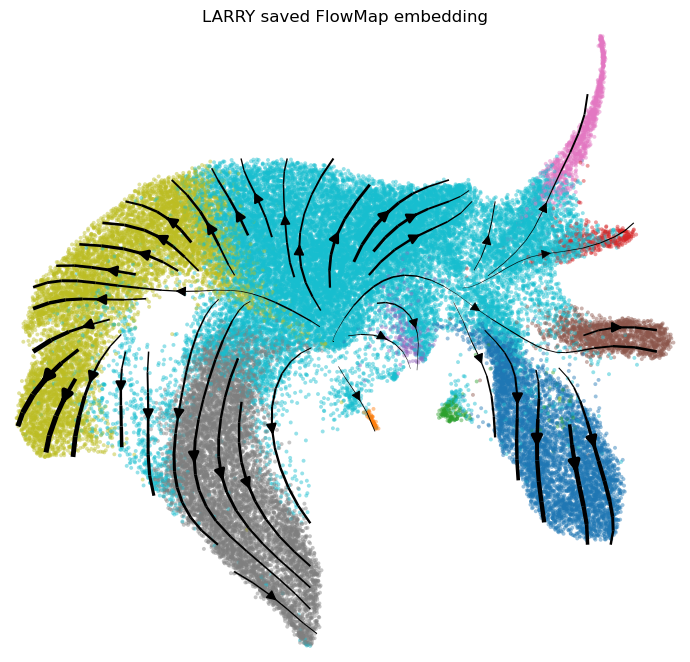

In [4]:
fig, ax = plt.subplots(figsize=(7, 7))
plot_velocity_stream(emb.X_emb, spline=emb.spline_vf, scatter_color=labels, scatter_size=8, scatter_alpha=0.45, ax=ax)
ax.set_title("LARRY saved FlowMap embedding")
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(FIG_DIR / "larry_saved_embedding_stream.png", dpi=300, bbox_inches="tight")
plt.show()